# Portfolio Optimisation Using Frank Wolfe Variants


## Brief description of what we want to do

- We have n available assets.
- We call xi the quantity of money invested on the i-th asset during the
considered period and with ri the returns on the i-th asset.
- We have two different constraints:
    - Non-negativity for the variables (i.e., xi ≥ 0). Meaning that short selling (selling asset that we still don’t own) is not allowed.
    - Budget constraint: $\sum_{i = 1}^{n} = B$, the total amount of money invested needs to be equal to the budget B (B can be simply set to 1).

- $r \in \mathbb{R}^n $ is a randomly generated vector with mean $\hat{r}$ and covariance $\sum$

- Expected return will be $\hat{r}^Tx$ and variance $x^T\sum x$
- Classic portfolio problem, described by Markowits (1952), is a convex quadratic
programming problem:
$$
\begin{aligned}
\min_{x \in \mathbb{R}^n} \quad & \gamma x^\top \Sigma x - \bar{r}^\top x \\
\text{s.t.} \quad & e^\top x = 1 \\
& x \ge 0
\end{aligned}
$$
- with $\gamma > 0$ risk-aversion parameter.
- GOAL: Finding the set of assets that minimises the variance (risk connected to the given portfolio) while maximising the expected return (we obviously need to satisfy budget and non-negativity constraints).

## Import Libraries and Data

In [49]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import Oracle 
importlib.reload(Oracle)
from Oracle import PortfolioOptimisation_rolling, PortfolioOptimisation_Whole_Dataset
import time
from scipy.stats import skew, kurtosis

dataset_paths = {
    'DowJones': 'DowJones.xlsx',
    'FTSE100': 'FTSE100.xlsx',
    'S&P 500': 'SP500.xlsx'
}
datasets = {}

for name, path in dataset_paths.items():

    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    datasets[name] = data
    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    print(f"Number of Missing values: {data.isna().sum().sum()}")




Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Number of Missing values: 0

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Number of Missing values: 0

Dataset: S&P 500
Number of assets: 442
Number of time periods: 595
Number of Missing values: 0


## Initial EDA

### Asset Return Statistics

In [50]:
asset_return_stats = []

for name, data in datasets.items():

    average_returns = data.mean(axis=0, skipna=True)


    asset_return_stats.append({
        'Dataset': name,
        'Number of Assets': len(average_returns),
        'Mean Average Return': average_returns.mean(),
        'Median Average Return': average_returns.median(),
        'Std Average Return': average_returns.std(ddof=1),
        'Minimum Average Return': average_returns.min(),
        'Maximum Average Return': average_returns.max(),
        'Skewness': skew(average_returns),
        'Kurtosis': kurtosis(average_returns)
    })


asset_return_stats_df = pd.DataFrame(asset_return_stats)

print(asset_return_stats_df.to_string(index=False))

 Dataset  Number of Assets  Mean Average Return  Median Average Return  Std Average Return  Minimum Average Return  Maximum Average Return  Skewness  Kurtosis
DowJones                28             0.002885               0.002506            0.001258                0.001278                0.006054  1.288624  0.671913
 FTSE100                83             0.002508               0.002507            0.001506               -0.000610                0.008018  0.807218  1.337827
 S&P 500               442             0.002546               0.002339            0.001471               -0.000626                0.010325  1.499171  4.517561


### Dataset Summary

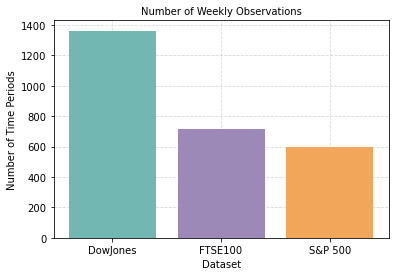

In [51]:

summary = []
for name, data in datasets.items():
    values = data.to_numpy().flatten()
    summary.append({
        "Dataset": name,
        "Number of Assets": data.shape[1],
        "Number of Time Periods": data.shape[0],
        "Total Observations": data.size,
        "Mean Return": np.mean(values),
        "Median Return": np.median(values),
        "Std Return": np.std(values, ddof=1),
        "Minimum Return": np.min(values),
        "Maximum Return": np.max(values),
        "Skewness": skew(values),
        "Kurtosis": kurtosis(values)
    })


summary_df = pd.DataFrame(summary)

x = summary_df["Dataset"]
y = summary_df["Number of Time Periods"]



plt.title(
    "Number of Weekly Observations",
    fontsize = 10
)

plt.xlabel("Dataset")
plt.ylabel("Number of Time Periods")
bars = plt.bar(x, y, color=["#72B7B2", "#9C89B8", "#F2A65A"],zorder=2)

plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)



### Correlation

In [52]:

correlation_results = []

for name, data in datasets.items():
    corr = data.corr()  
    upper_values = corr.values[np.triu_indices_from(corr.values, k=1)]
    upper_values = upper_values[np.isfinite(upper_values)]    
    correlation_results.append({
        "Dataset": name,
        "Mean Correlation": np.mean(upper_values),
        "Median Correlation": np.median(upper_values),
        "Minimum Correlation": np.min(upper_values),
        "Maximum Correlation": np.max(upper_values)
    })

correlation_df = pd.DataFrame(correlation_results)

print(correlation_df.to_string(index=False))



 Dataset  Mean Correlation  Median Correlation  Minimum Correlation  Maximum Correlation
DowJones          0.336582            0.325762             0.100503             0.787045
 FTSE100          0.345084            0.338179            -0.089827             0.845918
 S&P 500          0.412351            0.406816            -0.008174             0.984175


## Initial Results Per Algorithm

In [53]:
dataset_paths = {
    'DowJones': 'DowJones.xlsx', 
    'FTSE100': 'FTSE100.xlsx',
    'S&P500': 'SP500.xlsx'
}

all_results = {}
summary_list = []

for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values
    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    
    model = PortfolioOptimisation_Whole_Dataset(Sigma=Sigma, r_bar=r_bar, gamma =1)

    results = model.run_all_fw(max_iter=10000, tol=1e-6)
    all_results[name] = results

    for variant, result in results.items():
        history = result['history']
        summary_list.append({
            'Dataset': name,
            'Algorithm': variant,
            'Num Assets (n)': data.shape[1],
            'Time Periods (T)': data.shape[0],
            'Iterations': len(history),
            'Final Objective': history['Objective'].iloc[-1],
            'Final Duality Gap': history['Duality Gap'].iloc[-1],
            'Active Size (final)': history['Active Set Size'].iloc[-1],
            'Time (s)': result['time']
        })

    
summary_df = pd.DataFrame(summary_list)
print("\n" + summary_df.to_string(index=False))

Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Dataset: S&P500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones        FW              28              1363          29        -0.004183       9.447384e-07                    4  0.005213
DowJones      ASFW              28              1363           9        -0.004183       6.307742e-08                    4  0.001993
DowJones      PWFW              28              1363          13        -0.004183       3.594216e-07                    4  0.001999
 FTSE100        FW              83               717        4172        -0.005239       9.939590e-07                    5  0.472910
 FTSE100      ASFW              83               717          11        -0.005240       3.355678e-07                    4  0.002013
 FTSE10

## Some Graphics 

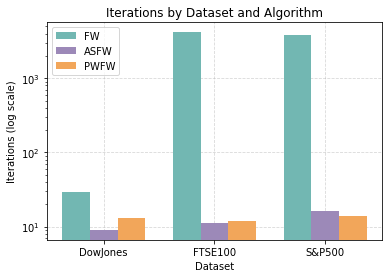

In [54]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["FW", "ASFW", "PWFW"]
datasets = summary_df["Dataset"].unique()

x = np.arange(len(datasets))
width = 0.25

colours = ["#72B7B2", "#9C89B8", "#F2A65A"]

for i, m in enumerate(methods):
    subset = summary_df[summary_df["Algorithm"] == m].set_index("Dataset")
    values = subset.reindex(datasets)["Iterations"]

    plt.bar(x + (i - 1) * width, values, width, label=m, color=colours[i], zorder=2)

plt.yscale("log")

plt.xlabel("Dataset")
plt.ylabel("Iterations (log scale)")
plt.title("Iterations by Dataset and Algorithm")
plt.xticks(x, datasets)

plt.legend()
plt.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)



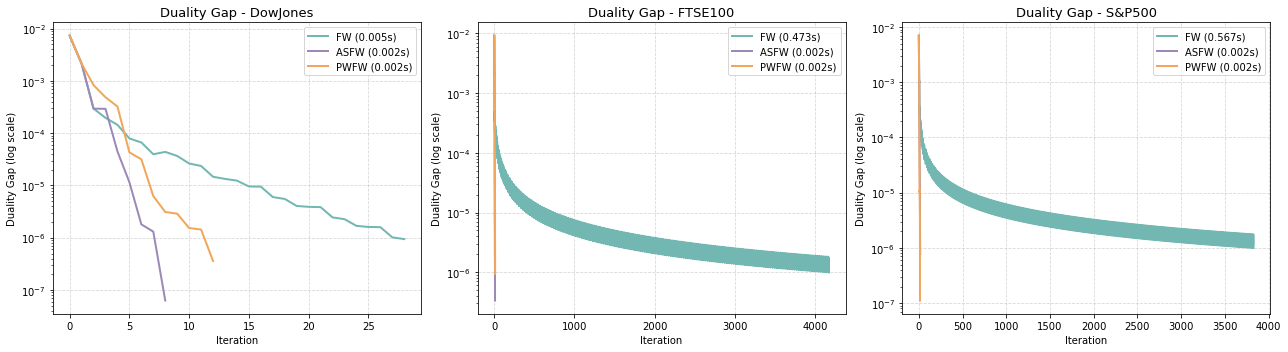

In [58]:
colours = ["#72B7B2", "#9C89B8", "#F2A65A"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, results) in enumerate(all_results.items()):

    ax = axes[idx]

    for i, (variant, result) in enumerate(results.items()):

        history = result["history"]

        ax.semilogy(
            history["Iteration"],
            history["Duality Gap"],
            label=f"{variant} ({result['time']:.3f}s)",
            linewidth=2,
            color=colours[i],
            zorder=2
        )

    ax.set_title(f"Duality Gap - {name}", fontsize=13)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Duality Gap (log scale)")
    ax.legend()
    ax.grid(axis="both", linestyle="--", alpha=0.5, zorder=1)

plt.tight_layout()
plt.show()